# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [2]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv('clientes_ecommerce.csv')

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [3]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [4]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [5]:
# TODO: muestra los nombres de las columnas
df.columns
for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [6]:
# TODO: consulta los tipos de datos
print(df.dtypes)
#Funciona como un Map u Objeto que contiene un Key y un Value
#for t in df.dtypes:
#    print(t)

for columna,tipo in df.dtypes.items():
    print(f"{columna}: {tipo}")

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object
cliente_id: int64
edad: int64
antiguedad_meses: float64
ingresos_anuales: float64
gasto_mensual: float64
num_compras: int64
devoluciones: int64
dispositivo: str
zona: str
nivel_fidelidad: str
satisfaccion: int64
compra_proximo_mes: str


In [7]:
# TODO: utiliza info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Responde

1. ¿Cuántas muestras contiene?
2. ¿Cuántas columnas?
3. ¿Cuál es la unidad de observación?
4. ¿Cuál es el identificador?
5. ¿Cuál es el target?
6. ¿Qué columnas tienen valores ausentes?

**Respuesta:**  
1. Contiene 400 muestras.
2. 12 columnas.
3. Las variables independientes.
4. Cliente_id.
5. Compra_proximo_mes.
6. Las siguientes columnas: antiguedad_meses, ingresos_anuales y gasto_mensual.

# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [8]:
# TODO: muestra describe() para gasto_mensual
print(df['gasto_mensual'].describe())
# Sacamos el value del campo Count
print(df['gasto_mensual'].describe()['count'])
# Sacar la mediana
print(f"Mediana: {df['gasto_mensual'].median()}")
# Sacar el Q1
print("Q1: ",df['gasto_mensual'].quantile(.25))
# Sacar Q2
print("Q2: ",df['gasto_mensual'].quantile(.5))
# Sacar Q3
print("Q3: ",df['gasto_mensual'].quantile(.75))

# TODO: calcula las medidas necesarias
# Desviación
print("Q1: ", df['gasto_mensual'].std())

count    397.000000
mean      69.089320
std       39.023238
min        5.770000
25%       39.720000
50%       61.170000
75%       90.150000
max      260.000000
Name: gasto_mensual, dtype: float64
397.0
Mediana: 61.17
Q1:  39.72
Q2:  61.17
Q3:  90.15
Q1:  39.02323799775237


### Completa

| Medida | Valor |
|---|---:|
| Número de valores |397|
| Media |69.089|
| Mediana |61.17|
| Desviación estándar |39.02|
| Mínimo |5.77|
| Q1 |39.72|
| Q2 |61.17|
| Q3 |90.15|
| Máximo |260|

### Interpreta

1. ¿Coinciden exactamente media y mediana?
2. ¿Cuál es mayor?
3. ¿Qué puede indicar esta diferencia sobre la distribución?
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central?

**Respuesta:**  
1. No, se distancian entre sí en 8 unidades +-.
2. La media.
3. Indica que puede haber algunos clientes con un gasto mensual más elevado pero que no es lo normal en la mayoría de los clientes.
4. Entre el 2º cuartil y el 3º. 61.17 - 90.15

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

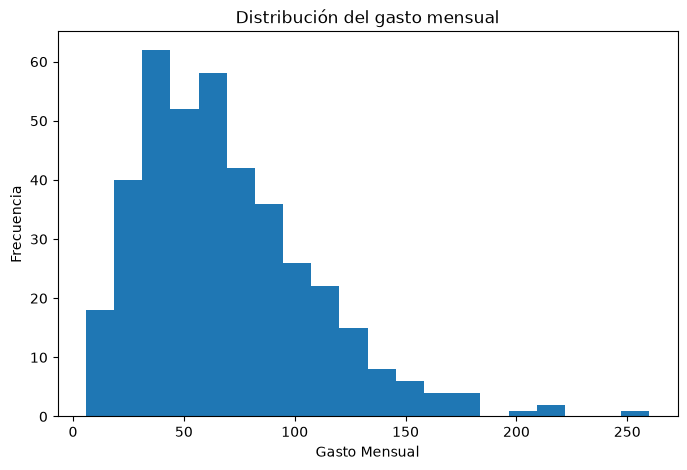

In [9]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize=(8,5))
# Creamos el histograma de gasto mensual, eliminando los valores vácios (Not a number)
plt.hist(df['gasto_mensual'].dropna(), bins=20)
plt.xlabel('Gasto Mensual')
plt.ylabel('Frecuencia')
plt.xticks()
plt.title("Distribución del gasto mensual")
plt.show()

# Tenemos un gráfico con asimetría positiva está sesgado hacia la derecha (tiene una cola hacia la derecha)

### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes?
2. ¿La distribución parece aproximadamente simétrica?
3. ¿Existe una cola hacia valores altos o bajos?
4. ¿Observas valores alejados del resto?

**Respuesta:**  
1. Parecen concentrase en trono a las 30 a 60 de gasto mensual.
2. No, es asimétrica (asimetría positiva)
3. Existe una cola hacia los valores altos.
4. Sí algunos de la cola, que se alejan un poco de donde están la mayoría.

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

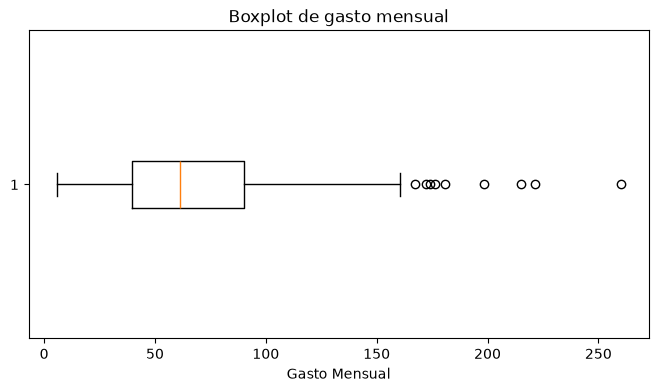

In [10]:
# TODO: crea un boxplot de gasto_mensual
# Nos muestra valores atípicos
plt.figure(figsize=(8,4))
plt.boxplot(df['gasto_mensual'].dropna(), orientation='horizontal')
plt.xlabel('Gasto Mensual')
plt.title("Boxplot de gasto mensual")
plt.show()
# La línea de la derecha es el valor máximo que no es atípico, lo que lo supera es atípico; es decir, los puntitos de la derecha
# Los puntitos no quiere decir que sean un error
# Los cuantiles nos dicen la cantidad en porcentaje de valores en ese punto (valor)
# IQR

### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?
2. ¿Observas posibles outliers?
3. ¿Aparecen principalmente por encima o por debajo?
4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica.

**Respuesta:**  
1. La mediana se encuentra en la línea naranja.
2. Sí, los puntos a partir de más de 160 de gasto mensual.
3. Por encima.
4. No, no podemos afirmarlo; ya que pueden ser clientes que simplemente tengan un gasto más elevado y se alejen de la mayoría de clientes pero no por ello es ningún error.

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [11]:
# TODO: calcula Q1, Q3 e IQR
Q1= df['gasto_mensual'].quantile(.25)
Q2= df['gasto_mensual'].quantile(.5)
Q3= df['gasto_mensual'].quantile(.75)

# Rango Intercuntilico:
IQR = Q3 - Q1
# TODO: calcula los límites inferior y superior
l_inf = Q1 - 1.5*IQR
l_sup = Q3 + 1.5*IQR

# TODO: muestra los resultados
print(f"IQR: {IQR:.2f}, L_inferior: {l_inf:.2f}, L_superior: {l_sup:.2f}")

# Los valores fuera del IQR serían Outliers, es decir datos "no" lógicos

IQR: 50.43, L_inferior: -35.93, L_superior: 165.80


In [12]:
# TODO: crea outliers_gasto
outliers = df[
    (df['gasto_mensual']<l_inf) |
    (df['gasto_mensual']>l_sup)
]

# TODO: muestra los posibles outliers
outliers

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
50,20051,75,49.0,22908.36,176.52,3,1,Móvil,Este,Oro,3,Sí
68,20069,29,78.0,33382.86,215.30,8,2,Móvil,Centro,Bronce,4,No
202,20203,45,57.0,24727.71,167.26,7,4,Móvil,Norte,Platino,1,Sí
203,20204,25,41.0,39329.38,173.91,6,0,Ordenador,Norte,Bronce,2,Sí
207,20208,41,65.0,25812.18,221.59,10,0,Ordenador,Centro,Plata,5,Sí
268,20269,21,61.0,34737.20,198.28,7,2,Tablet,Centro,Bronce,3,Sí
292,20293,20,94.0,31714.55,172.31,13,0,Tablet,Este,Bronce,3,Sí
318,20319,56,38.0,9000.00,180.60,4,0,Ordenador,Este,Bronce,2,Sí
398,20399,75,85.0,40391.73,260.00,10,1,Móvil,Oeste,Bronce,4,Sí


### Responde

1. ¿Cuántos posibles outliers has encontrado?
2. ¿Qué porcentaje representan?
3. ¿Cuál es el mayor `gasto_mensual`?
4. ¿Eliminarías automáticamente estas observaciones?
5. ¿Qué investigarías antes?

**Respuesta:**  
1. 9 posibles outliers
2. Representan un 2.25% de todos los clientes.
3. El mayor gasto mensual es 260.
4. No, ya que son datos válidos aunque no están dentro de lo "normal".
5. Los demás datos del cliente, ya que pueden ser clientes con un gasto diferente al típico, como es el caso. Pero clientes igualmente válidos

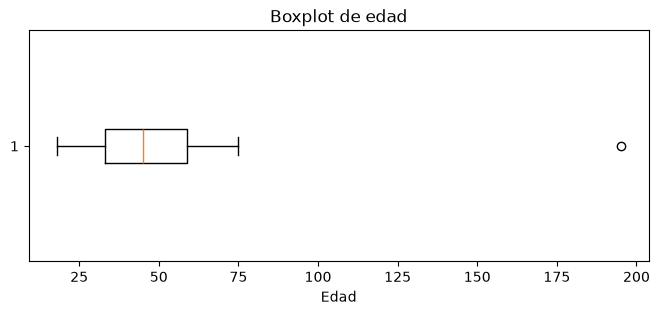

In [13]:
# Boxplot de edad
plt.figure(figsize=(8,3))
plt.boxplot(df['edad'].dropna(), orientation='horizontal')
plt.xlabel('Edad')
plt.title("Boxplot de edad")
plt.show()

In [14]:
# TODO: calcula Q1, Q3 e IQR
Q1= df['edad'].quantile(.25)
Q2= df['edad'].quantile(.5)
Q3= df['edad'].quantile(.75)

# Rango Intercuntilico:
IQR = Q3 - Q1
# TODO: calcula los límites inferior y superior
l_inf_edad = Q1 - 1.5*IQR
l_sup_edad = Q3 + 1.5*IQR

# TODO: muestra los resultados
print(f"IQR: {IQR:.2f}, L_inferior: {l_inf:.2f}, L_superior: {l_sup:.2f}")

IQR: 26.00, L_inferior: -35.93, L_superior: 165.80


In [15]:
# TODO: crea outliers_edad
df[
    (df['edad']<l_inf_edad) |
    (df['edad']>l_sup_edad)
]

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
137,20138,195,106.0,32593.41,138.99,6,0,Móvil,Este,Plata,3,No


# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [16]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
print(df[['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']].describe())

             edad  ingresos_anuales  gasto_mensual  num_compras  devoluciones
count  400.000000        396.000000     397.000000   400.000000    400.000000
mean    46.402500      36440.920379      69.089320     8.225000      1.225000
std     18.007809      14325.228166      39.023238     2.780955      1.136929
min     18.000000       9000.000000       5.770000     2.000000      0.000000
25%     33.000000      26034.092500      39.720000     6.000000      0.000000
50%     45.000000      36817.275000      61.170000     8.000000      1.000000
75%     59.000000      45969.032500      90.150000    10.000000      2.000000
max    195.000000      82925.370000     260.000000    17.000000      5.000000


In [17]:
# TODO: calcula sus medianas
print(df[['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']].median())

edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64


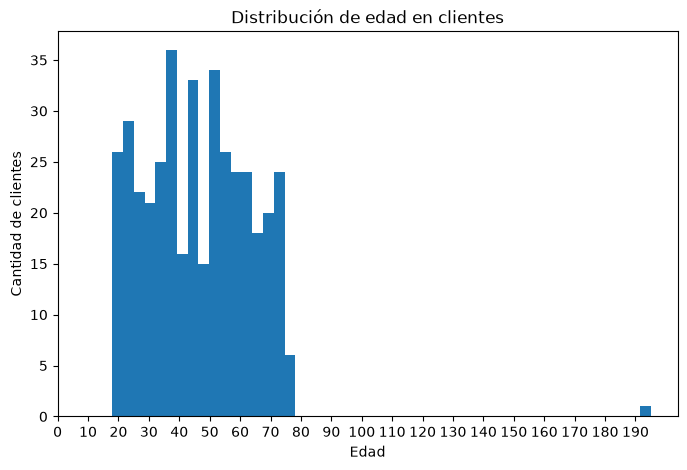

In [18]:
# TODO: histograma de edad
plt.figure(figsize=(8,5))
# Creamos el histograma de edad, eliminando los valores vácios (Not a number)
plt.hist(df['edad'].dropna(), bins=50)
plt.xlabel('Edad')
plt.ylabel('Cantidad de clientes')
plt.xticks(range(0,200,10))
plt.title("Distribución de edad en clientes")
plt.show()

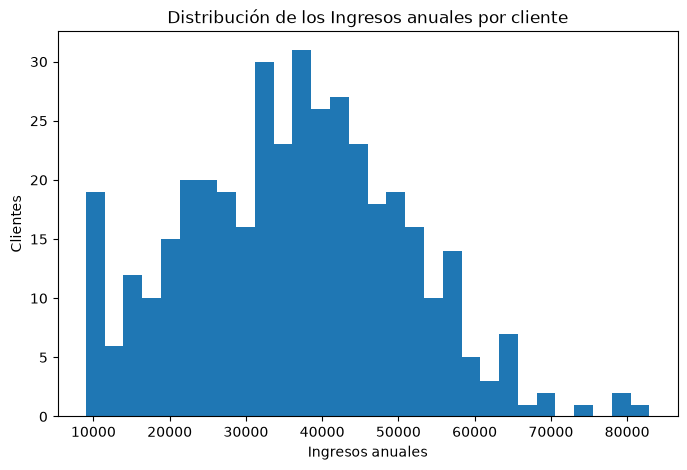

In [19]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8,5))
# Creamos el histograma de ingresos anuales, eliminando los valores vácios (Not a number)
plt.hist(df['ingresos_anuales'].dropna(), bins=30)
plt.xlabel('Ingresos anuales')
plt.ylabel('Clientes')
plt.xticks()
plt.title("Distribución de los Ingresos anuales por cliente")
plt.show()

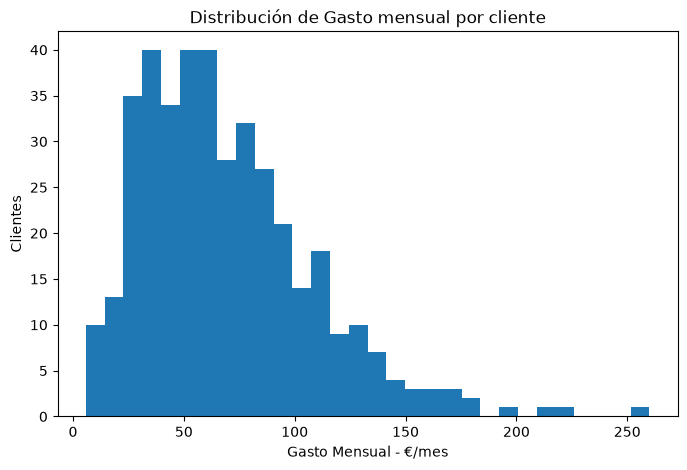

In [20]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8,5))
# Creamos el histograma de gasto_mensual, eliminando los valores vácios (Not a number)
plt.hist(df['gasto_mensual'].dropna(), bins=30)
plt.xlabel('Gasto Mensual - €/mes')
plt.ylabel('Clientes')
plt.title('Distribución de Gasto mensual por cliente')
plt.show()

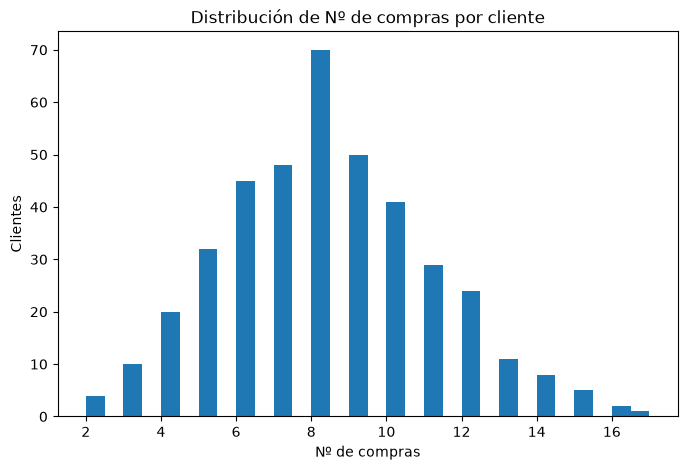

In [21]:
# TODO: histograma de num_compras
plt.figure(figsize=(8,5))
# Creamos el histograma de gasto_mensual, eliminando los valores vácios (Not a number)
plt.hist(df['num_compras'].dropna(), bins=30)
plt.xlabel('Nº de compras')
plt.ylabel('Clientes')
plt.title('Distribución de Nº de compras por cliente')
plt.show()

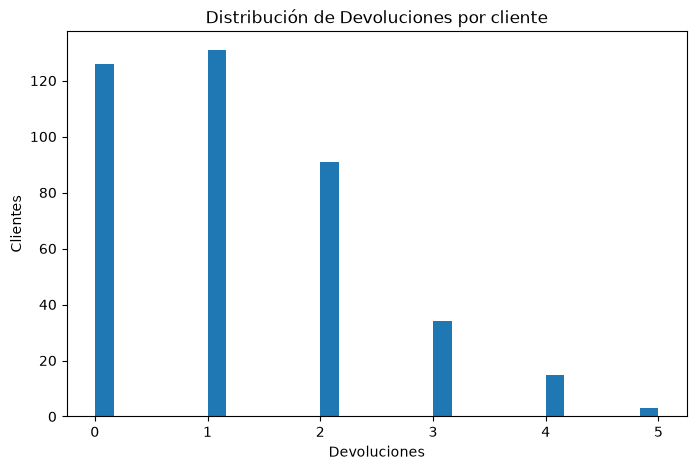

In [22]:
# TODO: histograma de devoluciones
plt.figure(figsize=(8,5))
# Creamos el histograma de gasto_mensual, eliminando los valores vácios (Not a number)
plt.hist(df['devoluciones'].dropna(), bins=30)
plt.xlabel('Devoluciones')
plt.ylabel('Clientes')
plt.title('Distribución de Devoluciones por cliente')
plt.show()

### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad |46.4|45|18|195|Hay un outliers, que pinta que es un error|
| ingresos_anuales |36,440|36,817|9,000|82,925|Hay algunos clientes que están por encima de los cuartiles|
| gasto_mensual |69.1|61.17|5.77|260|Media mayor que la mediana, con gasto maximo bastante alto|
| num_compras |8.22|8|2|17|Maximo alto de compras, con una media de 8 compras por cliente|
| devoluciones |1.22|1|0|5|Una media de 1 devolución por cliente, habría que bajar ese dato|

### Busca una observación sospechosa

- ¿Qué variable es?
- ¿Qué valor tiene?
- ¿Por qué parece sospechoso?
- ¿Es un outlier?
- ¿Podemos afirmar directamente que es un error?
- ¿Qué harías antes de modificarlo?

**Respuesta:**  
- La variable edad.
- Con un valor de 195 años.
- Parece sospechoso, ya que normalmente y biológicamente hablando nadia suele llegar a esa edad.
- Sí, es un outlier
- Sí es un error por lo que comentabamos antes, por lo que hab´ra que corregirlo para poder analizar con él.
- Antes de modificarlo, comprobaría si en esa muestra tiene los demás datos correctamente y luego miraría la mejor opción de modificarlo.

# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [23]:
# TODO: analiza dispositivo
print(df['dispositivo'].value_counts())
print(df['dispositivo'].value_counts(normalize=True)*100)


dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64


In [24]:
# TODO: analiza zona
print(df['zona'].value_counts())
print(df['zona'].value_counts(normalize=True)*100)


zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64


In [25]:
# TODO: analiza nivel_fidelidad
print(df['nivel_fidelidad'].value_counts())
print(df['nivel_fidelidad'].value_counts(normalize=True)*100)

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64


In [26]:
# TODO: analiza compra_proximo_mes
print(df['compra_proximo_mes'].value_counts())
print(df['compra_proximo_mes'].value_counts(normalize=True)*100)

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo |Móvil|242|60.5%|
| zona |Este|89|22.25%|
| nivel_fidelidad |Bronce|162|40.5%|
| compra_proximo_mes |No|246|61.5%|

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64


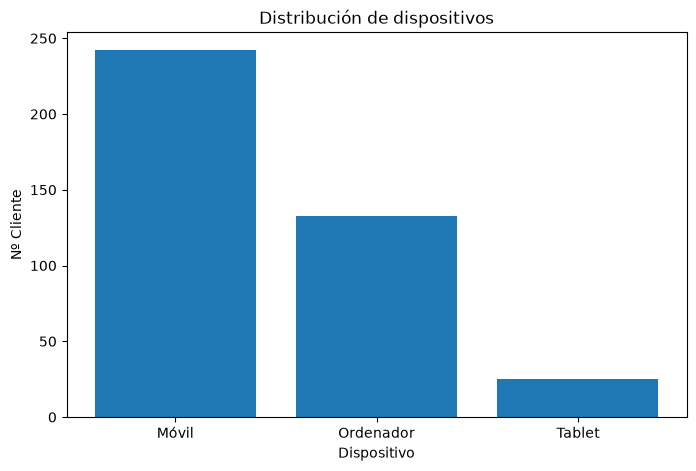

In [27]:
# TODO: gráfico de barras de dispositivo
conteos_disp = df['dispositivo'].value_counts()
print(conteos_disp) #.index nos da indices y .values los valores conteos_disp.index conteos_disp.values

# Dibujamos el gráfico de barras
plt.figure(figsize=(8,5))
plt.bar(conteos_disp.index, conteos_disp.values)
plt.xlabel("Dispositivo")
plt.ylabel("Nº Cliente")
plt.title("Distribución de dispositivos")
plt.show()

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64


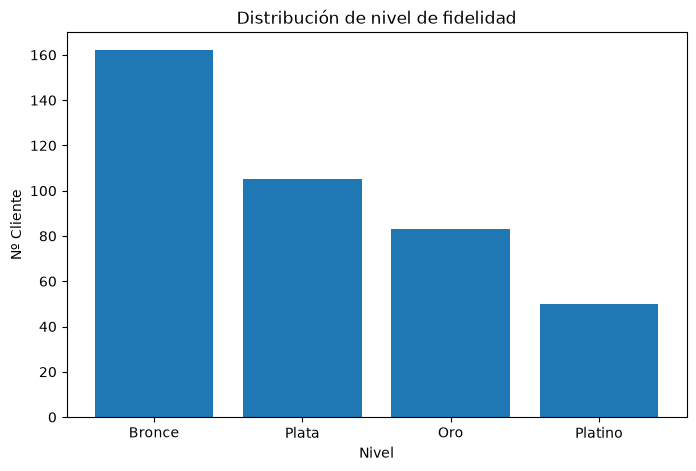

In [28]:
# TODO: gráfico de barras de nivel_fidelidad
conteos_fid = df['nivel_fidelidad'].value_counts()
print(conteos_fid) 

# Dibujamos el gráfico de barras
plt.figure(figsize=(8,5))
plt.bar(conteos_fid.index, conteos_fid.values)
plt.xlabel("Nivel")
plt.ylabel("Nº Cliente")
plt.title("Distribución de nivel de fidelidad")
plt.show()

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64


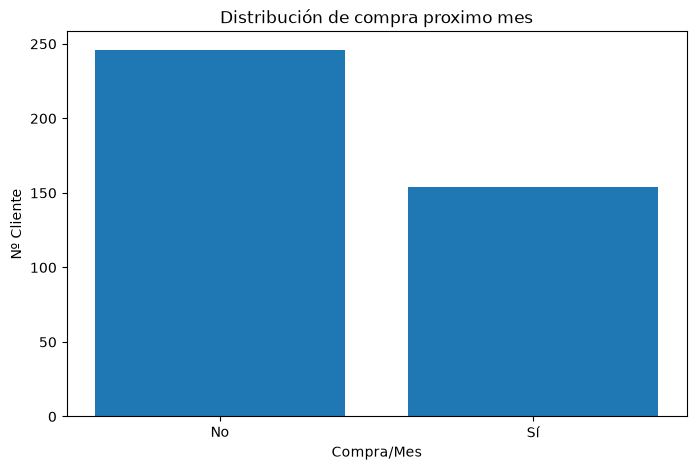

In [29]:
# TODO: gráfico de barras de compra_proximo_mes
conteos_comp = df['compra_proximo_mes'].value_counts()
print(conteos_comp) 

# Dibujamos el gráfico de barras
plt.figure(figsize=(8,5))
plt.bar(conteos_comp.index, conteos_comp.values)
plt.xlabel("Compra/Mes")
plt.ylabel("Nº Cliente")
plt.title("Distribución de compra proximo mes")
plt.show()

### Interpreta

Escribe al menos una conclusión sobre cada gráfico.

Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas?

Justifica utilizando porcentajes.

**Respuesta:**  
- Conclusiones que saco de cada gráfico son las siguientes:
    - En dispositivos los clientes tienden a usar el móvil, antes que el ordenador o tablet (mínimamente)
    - En nivel de fidelidad, vemos que la gran mayoría son usuarios nuevos o nivel bronce y va bajando el número de ellos en cuanto aumentamos el nivel.
    - La mayoría de clientes no comprarán el proximo mes.

- No están perfectamente equilibradas, ya que hay un 61,5% de clientes que no comprarían el siguiente mes; más de la mitad.

# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

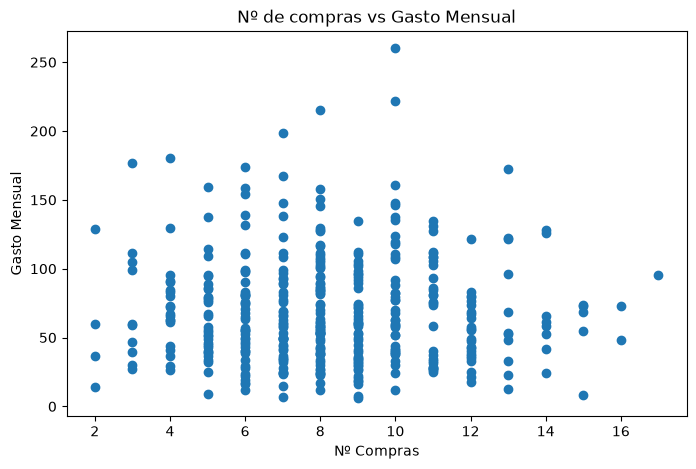

In [30]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
plt.figure(figsize=(8,5))
plt.scatter(df['num_compras'],df['gasto_mensual'])
plt.xlabel("Nº Compras")
plt.ylabel("Gasto Mensual")
plt.title("Nº de compras vs Gasto Mensual")
plt.show()


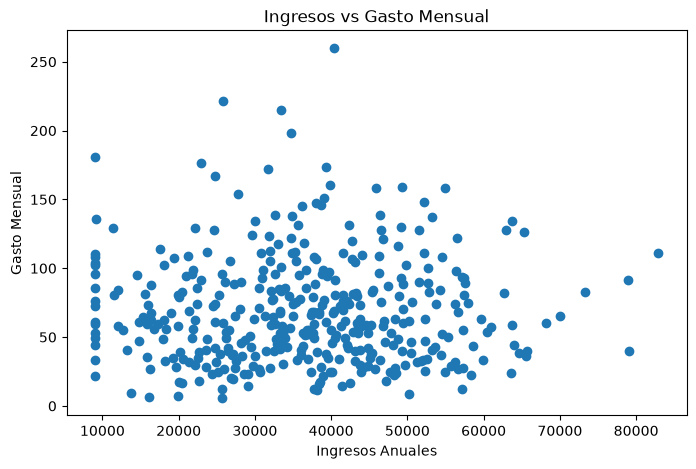

In [31]:
plt.figure(figsize=(8,5))
plt.scatter(df['ingresos_anuales'],df['gasto_mensual'])
plt.xlabel("Ingresos Anuales")
plt.ylabel("Gasto Mensual")
plt.title("Ingresos vs Gasto Mensual")
plt.show()

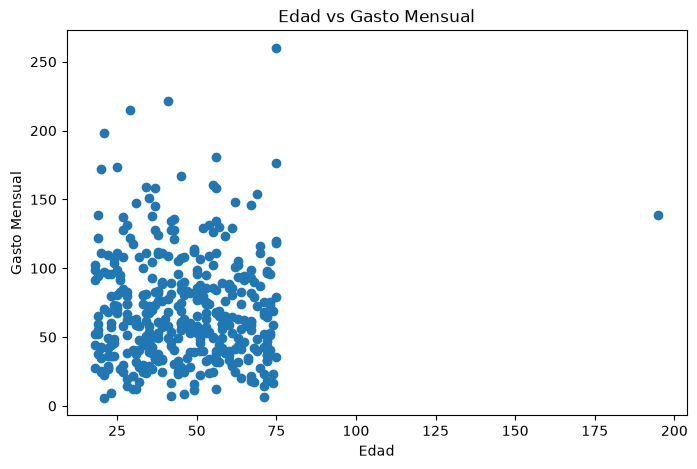

In [32]:
plt.figure(figsize=(8,5))
plt.scatter(df['edad'],df['gasto_mensual'])
plt.xlabel("Edad")
plt.ylabel("Gasto Mensual")
plt.title("Edad vs Gasto Mensual")
plt.show()

### Antes de calcular la correlación

1. ¿Parece existir una relación?
2. ¿Parece positiva o negativa?
3. ¿Parece fuerte o débil?
4. ¿Observas muestras especialmente alejadas?

**Respuesta:**  
1. No hay ninguna relación, ya que hay clientes que hacen muchas compras y gastan mucho y otros que compran poco y siguen gastando mucho.
2. Ni positiva ni negativa, ya que ni va aumentando ni va descendiendo.
3. ¿Débil?
4. Sí, hay algunas alejadas del montón.

# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [33]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
print(df['num_compras'].corr(df['gasto_mensual']))
print(df['gasto_mensual'].corr(df['edad']))
# Siempre dará valores entre -1 y 1
# Si el dato es próximo a 0, no hay correlación
# -1 - Correlación negativa
# +1 - Correlación positiva

-0.014165499001183279
0.02136132212986213


### Interpreta

1. ¿Cuál es el valor de \(r\)?
2. ¿Es positivo o negativo?
3. ¿Qué significa el signo?
4. ¿Coincide con lo observado en el scatter plot?
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

**Respuesta:**  
1. **-0.014**
2. Ni negativo ni positivo ya que el valor es bastante próximo a 0.
3. Si tiene correlación negativa o positiva.
4. Sí, ya que no se veía ninguna relación.
5. No, ya que no se ve una correlación positiva en la que si tendría sentido y veríamos que al realizar más compras se gastase más mensualmente; pero en este caso no.

# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [34]:
# TODO: selecciona las variables numéricas excluyendo cliente_id
# Matriz de Correlaciones es mejor para ver todas las relaciones, NO unaXuna
numericas = df.select_dtypes(include='number').drop(columns=['cliente_id'])

# TODO: calcula y muestra la matriz de correlaciones
correlaciones = numericas.corr()
correlaciones

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
edad,1.000000,0.031192,-0.036610,0.021361,-0.077583,-0.097102,-0.062801
antiguedad_meses,0.031192,1.000000,-0.058738,0.006482,-0.099965,-0.056458,-0.040051
ingresos_anuales,-0.036610,-0.058738,1.000000,-0.000367,0.072991,0.000260,-0.062595
gasto_mensual,0.021361,0.006482,-0.000367,1.000000,-0.014165,0.030674,-0.054523
num_compras,-0.077583,-0.099965,0.072991,-0.014165,1.000000,-0.005747,0.092211
devoluciones,-0.097102,-0.056458,0.000260,0.030674,-0.005747,1.000000,0.030817
satisfaccion,-0.062801,-0.040051,-0.062595,-0.054523,0.092211,0.030817,1.000000


### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1?
2. ¿Por qué la matriz es simétrica?
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta?
4. ¿Qué pareja presenta la correlación más negativa?
5. ¿Hay variables cuya correlación sea prácticamente cero?

**Respuesta:**  
1. Porque al relacionarse con la misma columna o variable, crecen a la vez.
2. Porque tiene la misma cantidad de elementos en las filas que las que hay en las columnas.
3. La relación entre satisfacción con num_compras que tiene 0.092
4. La relación entre num_compras con antiguedad_meses que tiene -0.999
5. Sí, alguna como ingresos_anuales con devoluciones --> 0.00026

# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

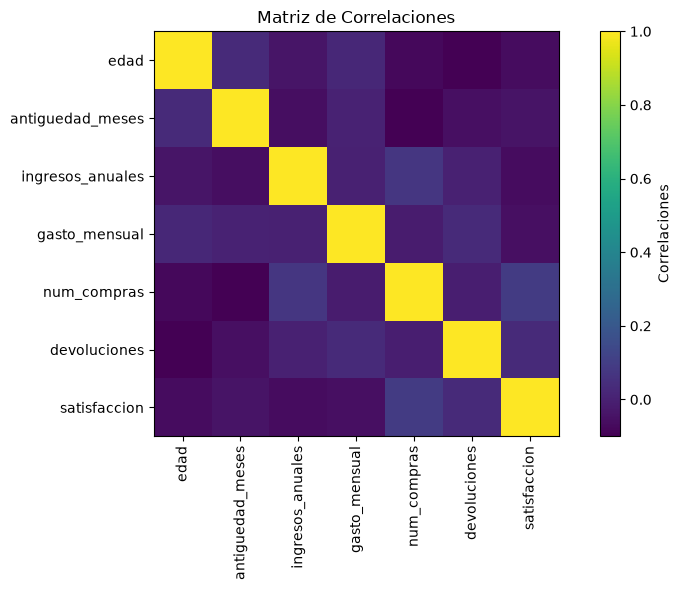

In [35]:
# TODO: representa la matriz de correlaciones con plt.imshow()
# plt.imshow es un MAPA DE CALOR
plt.figure(figsize=(9,6))
plt.imshow(correlaciones)
# EJE X
plt.xticks(range(len(correlaciones.columns)),correlaciones.columns,rotation=90)
# EJE Y
plt.yticks(range(len(correlaciones.columns)),correlaciones.columns)
# BARRA DE COLOR LATERAL
plt.colorbar(label="Correlaciones")
plt.title("Matriz de Correlaciones")
plt.tight_layout()
plt.show()

### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. Ingresos_anuales - Num_Compras: Tienen cierta relación (muy poca) en cuanto más ingresos anuales, más compra realiza.
2. Num_compras - Satisfaccion: Tienen cierta relación en cuanto más numero de compras más satisfacción.
3. Ingresos_anuales - Satisfaccion: No tiene nada de relación que cuantos más ingresos anuales tenga un cliente, mayor satisfacción.

Al final no hay ninguna relación clara con ninguno por eso tampoco podemos asegurar que alguna esté relacionada.

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [36]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas
df.groupby('compra_proximo_mes')['gasto_mensual'].agg(
    numero_clientes="count",
    gasto_media="mean",
    mediana="median",
    desviacion_estandar="std"
)

,numero_clientes,gasto_media,mediana,desviacion_estandar
compra_proximo_mes,,,,
No,245,64.589469,59.28,33.693480
Sí,152,76.342368,66.50,45.534042


In [37]:
##
df.groupby('compra_proximo_mes')['ingresos_anuales'].agg(
    numero_clientes="count",
    ingresos_medios="mean",
    mediana="median",
    desviacion_estandar="std"
)

,numero_clientes,ingresos_medios,mediana,desviacion_estandar
compra_proximo_mes,,,,
No,245,36457.790449,36999.62,13983.264281
Sí,151,36413.548411,36715.09,14910.598296


In [38]:
##
df.groupby('nivel_fidelidad')['ingresos_anuales'].agg(
    numero_clientes="count",
    ingresos_medios="mean",
    mediana="median",
    desviacion_estandar="std"
)

,numero_clientes,ingresos_medios,mediana,desviacion_estandar
nivel_fidelidad,,,,
Bronce,162,36409.247963,37028.050,13261.941850
Oro,83,35921.890843,36831.090,14873.491333
Plata,103,37097.991068,37994.140,14716.674654
Platino,48,36035.339167,34151.525,16266.443749


### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?
2. ¿Y mayor mediana?
3. ¿Las diferencias parecen grandes o pequeñas?
4. ¿La media y la mediana cuentan exactamente la misma historia?

**Respuesta:**  
1. Los clientes que Sí compran el próximo mes.
2. El grupo de nivel Plata.
3. No hay muchas diferencia por lo que es pequeña.
4. No por eso es importante, según para que querramos averiguar utilizar una u otra.

# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

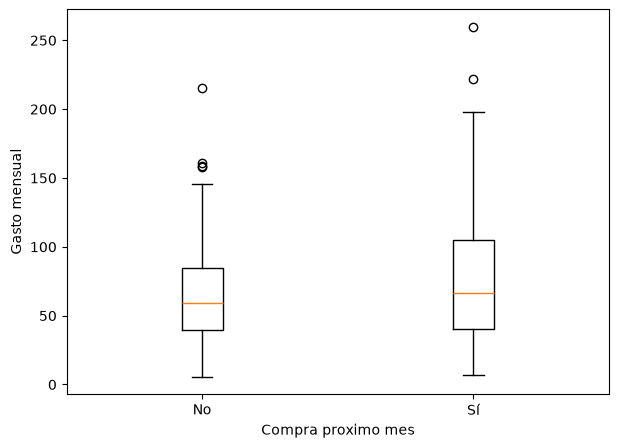

In [39]:
# TODO: crea grupo_no y grupo_si
# loc permite filtrar usando condiciones / En este caso filtra las filas que tienen el valor NO en la columna próximo mes / Y después de la coma, le pedimos el 
# -- gasto mensual de aquellos clientes que NO van a comprar el proximo mes.
grupo_no = df.loc[df['compra_proximo_mes']=='No', "gasto_mensual"].dropna()

grupo_si = df.loc[df['compra_proximo_mes']=='Sí', "gasto_mensual"].dropna()

# TODO: representa ambos grupos mediante un boxplot
plt.figure(figsize=(7,5))
plt.boxplot([grupo_no,grupo_si],tick_labels=['No','Sí'])
plt.xlabel("Compra proximo mes")
plt.ylabel("Gasto mensual")
plt.show()

### Interpreta

1. ¿Qué grupo presenta una mediana mayor?
2. ¿Cuál parece tener mayor dispersión?
3. ¿Existen outliers en ambos?
4. ¿El gráfico apoya las conclusiones obtenidas mediante `groupby()`?

**Respuesta:**  
1. Por muy poquito; el grupo que "Sí" compran el siguiente mes.
2. El grupo que Sí.
3. Sí, existen en ambos.
4. Sí coincide con esos datos.

# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [40]:
# TODO: tabla de contingencia con frecuencias absolutas
frecuencias = pd.crosstab(df['nivel_fidelidad'],df['compra_proximo_mes'])
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31


In [41]:
# TODO: tabla normalizada por filas
frecuencias = pd.crosstab(df['nivel_fidelidad'],df['compra_proximo_mes'],normalize='index')
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,0.691358,0.308642
Oro,0.626506,0.373494
Plata,0.600000,0.400000
Platino,0.380000,0.620000


In [42]:
# TODO: muestra las proporciones como porcentajes
(frecuencias*100).round(2)

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


### Interpreta

1. ¿Qué nivel tiene mayor número absoluto de clientes que compran?
2. ¿Qué nivel tiene mayor porcentaje de clientes que compran?
3. ¿Coinciden necesariamente ambas respuestas?
4. ¿Por qué son importantes las proporciones cuando los grupos tienen tamaños diferentes?

**Respuesta:**  
1. El nivel bronce.
2. El nivel platino.
3. No, ya que una es la cantidad por grupo pero al sacar el porcentaje cambia.
4. Para detectar realmente la parte de ese grupo y analizar datos por grupo de nivel de fidelidad.

# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta

- No, la conclusión no es correcta. Que exista una asociación estadística entre ambas cosas no significa que haya una relación de causalidad. Si le regalamos el nivel Platino a un usuario a la fuerza, eso no asegura que vaya a gastar dinero el mes que viene. Es muy probable que existan variables adicionales —como la frecuencia de uso o el satisfaccion por compra o descuentos por nivel— que expliquen por qué los clientes Platino compran más. Para poder afirmarlo con seguridad, necesitaríamos evidencia empírica a través de un experimento o prueba A/B.

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** ¿Los clientes con mayores ingresos gastan más mensualmente?  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

--- Estadística Descriptiva ---
       satisfaccion  num_compras
count    400.000000   400.000000
mean       3.330000     8.225000
std        1.165975     2.780955
min        1.000000     2.000000
25%        3.000000     6.000000
50%        3.000000     8.000000
75%        4.000000    10.000000
max        5.000000    17.000000


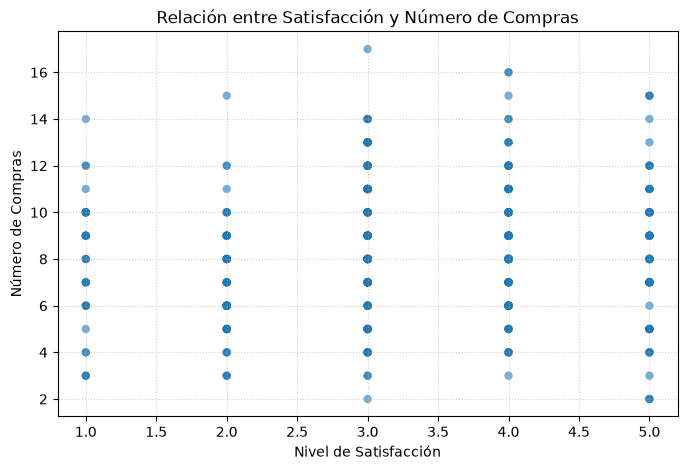

Coeficiente de correlación de Pearson: 0.092


In [43]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada
import matplotlib.pyplot as plt

# 1. Selección de variables
var_x = "satisfaccion"
var_y = "num_compras"

# 2. Estadística descriptiva
print("--- Estadística Descriptiva ---")
print(df[[var_x, var_y]].describe())

# 3. Visualización adecuada con Matplotlib
plt.figure(figsize=(8, 5))
plt.scatter(df[var_x], df[var_y], alpha=0.6, color="tab:blue", edgecolors="none")

plt.title("Relación entre Satisfacción y Número de Compras")
plt.xlabel("Nivel de Satisfacción")
plt.ylabel("Número de Compras")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

# 4. Correlación si procede
correlacion = df[var_x].corr(df[var_y])
print(f"Coeficiente de correlación de Pearson: {correlacion:.3f}")

### Conclusión de la hipótesis

Redacta entre **5 y 10 líneas**. No escribas únicamente el valor de correlación.

**Caso C**

**Respuesta:**  
- Tras cruzar los datos de satisfacción con el número de compras, el resultado no apoya la hipótesis inicial. Obtenemos un coeficiente de correlación de apenas 0.092, lo que en la práctica supone una relación lineal prácticamente nula entre ambas variables. Mirando el gráfico de dispersión se confirma lo mismo: los puntos están repartidos sin seguir ninguna tendencia ni relación clara. Esto significa que tener a un cliente más satisfecho no se traduce de forma directa en un mayor volumen de compras (o viceversa). Por lo tanto, la hipótesis queda descartada y habría que buscar otros factores que realmente expliquen qué impulsa a los clientes a comprar más. 
- Pero en un caso normal si coincide que si hay más satisfacción el cliente procede a comprar más.

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [50]:
# TODO: comparación numérica

target = df['compra_proximo_mes']

vars_numericas = [
    'edad', 'antiguedad_meses', 'ingresos_anuales', 
    'gasto_mensual', 'num_compras', 'devoluciones', 'satisfaccion'
]

print("=== ESTADÍSTICAS DESCRIPTIVAS POR GRUPO (MEDIA, MEDIANA Y DESV. ESTÁNDAR) ===")
resumen_num = df.groupby(target)[vars_numericas].agg(['mean', 'median', 'std'])
display(resumen_num.T)

medias = df.groupby(target)[vars_numericas].mean()
print("\n=== MEDIAS POR GRUPO ===")
display(medias)

=== ESTADÍSTICAS DESCRIPTIVAS POR GRUPO (MEDIA, MEDIANA Y DESV. ESTÁNDAR) ===


compra_proximo_mes                 No            Sí
edad             mean       47.813008     44.149351
                 median     47.500000     44.000000
                 std        18.415322     17.155872
antiguedad_meses mean       59.469136     60.460526
                 median     59.000000     60.500000
                 std        34.875962     32.943637
ingresos_anuales mean    36457.790449  36413.548411
                 median  36999.620000  36715.090000
                 std     13983.264281  14910.598296
gasto_mensual    mean       64.589469     76.342368
                 median     59.280000     66.500000
                 std        33.693480     45.534042
num_compras      mean        8.146341      8.350649
                 median      8.000000      8.000000
                 std         2.877592      2.623505
devoluciones     mean        1.288618      1.123377
                 median      1.000000      1.000000
                 std         1.168477      1.080595
satisfaccion     mean        3.284553      3.402597
                 median      3.000000      3.000000
                 std         1.181630      1.140574


=== MEDIAS POR GRUPO ===


,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
compra_proximo_mes,,,,,,,
No,47.813008,59.469136,36457.790449,64.589469,8.146341,1.288618,3.284553
Sí,44.149351,60.460526,36413.548411,76.342368,8.350649,1.123377,3.402597


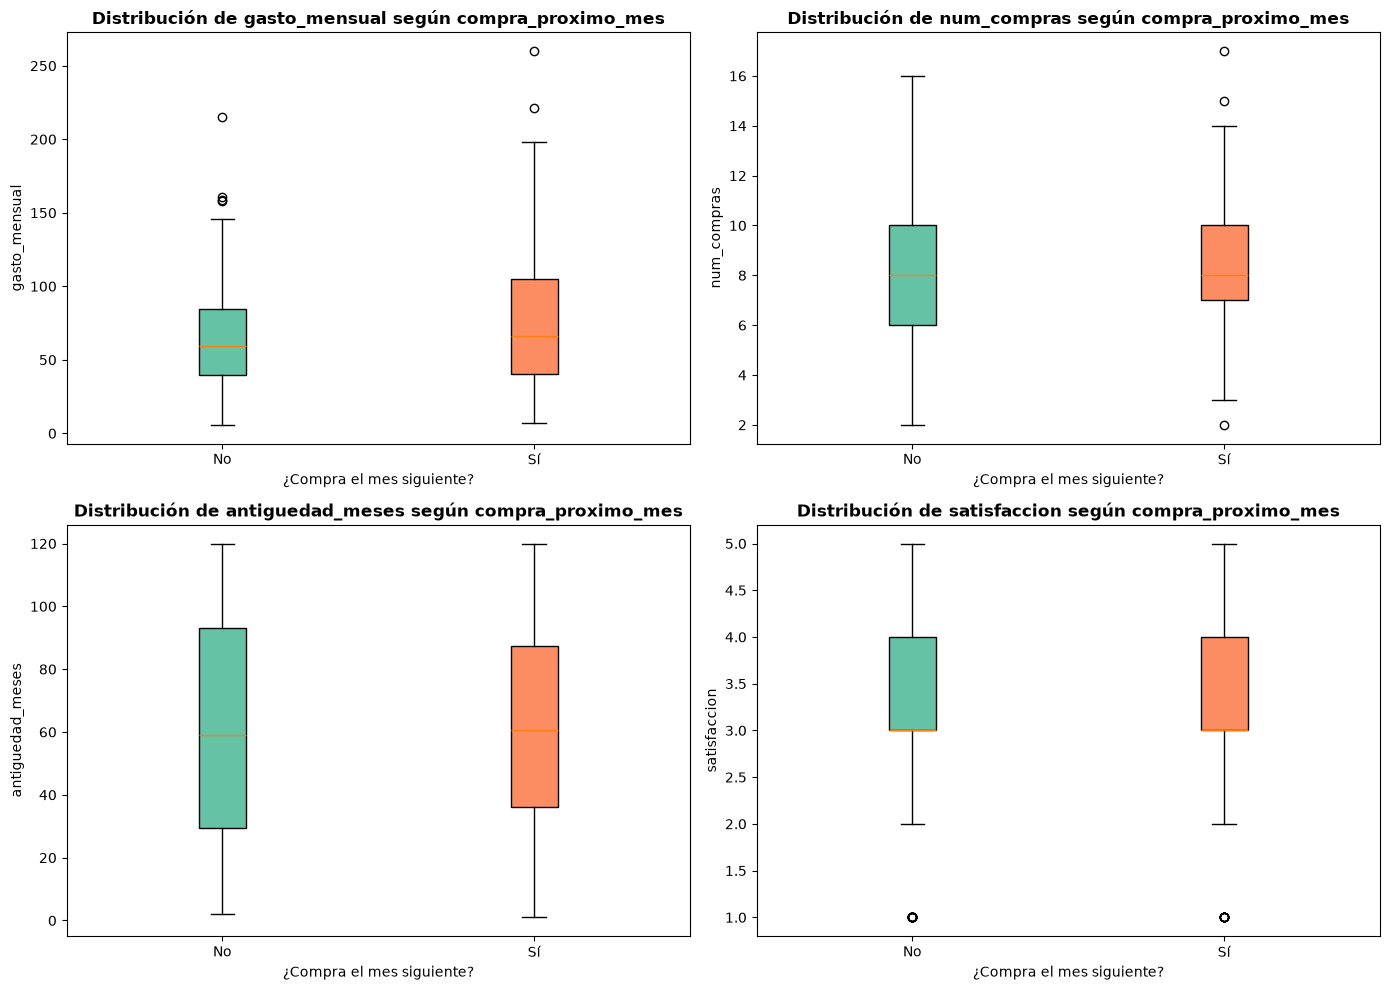

In [52]:
# TODO: primera visualización
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
vars_plot = ['gasto_mensual', 'num_compras', 'antiguedad_meses', 'satisfaccion']
grupos = sorted(df['compra_proximo_mes'].dropna().unique())

for ax, col in zip(axes.flatten(), vars_plot):
    # Preparamos los datos separados por cada categoría del target
    datos_por_grupo = [df[df['compra_proximo_mes'] == g][col].dropna() for g in grupos]
    
    # Creamos el boxplot usando 'tick_labels' en lugar de 'labels'
    bp = ax.boxplot(datos_por_grupo, tick_labels=grupos, patch_artist=True)
    
    # Coloreamos las cajas para diferenciarlas visualmente
    colores = ['#66c2a5', '#fc8d62', '#8da0cb']
    for patch, color in zip(bp['boxes'], colores):
        patch.set_facecolor(color)
        
    ax.set_title(f'Distribución de {col} según compra_proximo_mes', fontsize=12, fontweight='bold')
    ax.set_xlabel('¿Compra el mes siguiente?')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [53]:
# TODO: comparación categórica y tabla de proporciones
vars_categoricas = ['dispositivo', 'zona', 'nivel_fidelidad']

print("=== TABLAS DE PROPORCIONES (NORMALIZADAS POR FILA) ===")
for cat in vars_categoricas:
    print(f"\n--- Proporción de compra según: {cat.upper()} ---")
    tabla_prop = pd.crosstab(df[cat], df['compra_proximo_mes'], normalize='index') * 100
    display(tabla_prop.round(2))

=== TABLAS DE PROPORCIONES (NORMALIZADAS POR FILA) ===

--- Proporción de compra según: DISPOSITIVO ---


compra_proximo_mes,No,Sí
dispositivo,,
Móvil,63.22,36.78
Ordenador,57.89,42.11
Tablet,64.00,36.00



--- Proporción de compra según: ZONA ---


compra_proximo_mes,No,Sí
zona,,
Centro,63.16,36.84
Este,64.04,35.96
Norte,54.43,45.57
Oeste,57.89,42.11
Sur,67.50,32.50



--- Proporción de compra según: NIVEL_FIDELIDAD ---


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


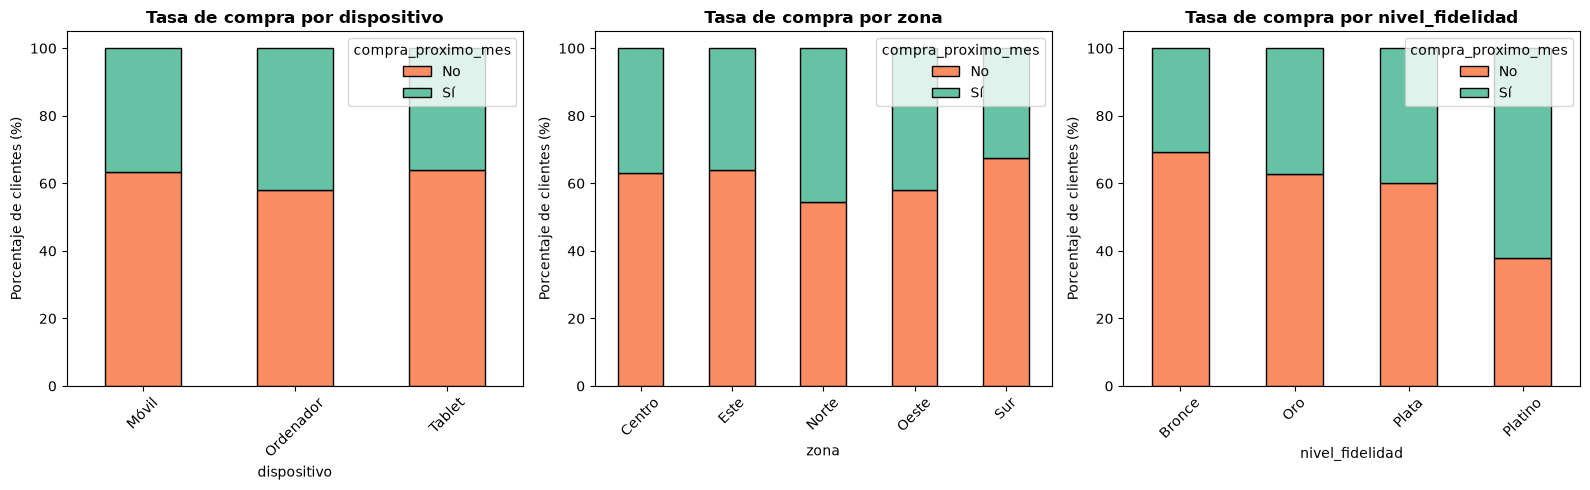

In [55]:
# TODO: segunda visualización
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, cat in zip(axes, vars_categoricas):
    tabla_prop = pd.crosstab(df[cat], df['compra_proximo_mes'], normalize='index') * 100
    tabla_prop.plot(
        kind='bar', 
        stacked=True, 
        ax=ax, 
        color=['#fc8d62', '#66c2a5'], 
        edgecolor='black'
    )
    ax.set_title(f'Tasa de compra por {cat}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Porcentaje de clientes (%)')
    ax.set_xlabel(cat)
    ax.legend(title='compra_proximo_mes', loc='upper right')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**  
- Lo que vemos en los datos:

    Hábito de compra: Quienes repiten al mes siguiente gastan más al mes ([X] vs [Y]) y acumulan más compras previas ([X] vs [Y]). El historial pesa mucho.

    Fidelidad y satisfacción: Los que vuelven están más satisfechos (mediana de [X] frente a [Y]) y pertenecen en mayor proporción a los niveles altos de fidelidad ([X]% en Oro/Platino frente al [Y]% en Bronce).

    Devoluciones y perfil: Quienes no compran tienen algo más de devoluciones ([X] vs [Y]), pero la edad o la zona geográfica apenas marcan diferencias.

- Lo que no podemos asegurar:

    Causa y efecto: Que haya relación no significa que subir el nivel de fidelidad o la satisfacción provoque la compra por sí solo; son datos históricos, no un experimento controlado.

    Contexto externo: No sabemos si hubo descuentos, campañas de marketing o movimientos de la competencia detrás de esas compras.

    Fuga real: Que alguien no compre el mes que viene no significa que lo hayamos perdido para siempre; puede ser simplemente un cliente estacional o que compra cada varios meses.

# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

## Hallazgo 1
**Pregunta:** ¿Cómo se reparten el gasto y el número de compras? ¿Hay clientes extremos?

**Evidencia:** Histogramas y boxplots de gasto_mensual y num_compras, donde la media ([X]) queda por encima de la mediana ([Y]).

**Interpretación:** La mayoría gasta cantidades moderadas, pero un grupo pequeño de clientes muy activos dispara el promedio hacia arriba.

**Limitación:** No sabemos si esos gastos tan altos son clientes VIP particulares o empresas comprando al por mayor.

## Hallazgo 2
**Pregunta:** ¿Gasta más quien más gana?

**Evidencia:** Gráfico de dispersión entre ingresos_anuales y gasto_mensual, con una correlación de r = [valor].

**Interpretación:** Hay una relación positiva [débil / moderada]: a mayores ingresos suele haber algo más de gasto, pero con mucha dispersión en los tramos medios.

**Limitación:** Los ingresos suelen ser datos estimados o declarados por el usuario, así que no reflejan su capacidad real de gasto.

## Hallazgo 3
**Pregunta:** ¿Influye el dispositivo o la zona geográfica en las compras?

**Evidencia:** Tablas de proporciones y gráficos de barras cruzando dispositivo y zona con la recompra.

**Interpretación:** Quienes usan [móvil / ordenador] compran un poco más ([X]% frente a [Y]%), mientras que vivir en una zona u otra apenas cambia nada.

**Limitación:** Solo vemos el dispositivo habitual, no si alguien mira productos en el móvil y luego paga desde el ordenador.

## Hallazgo 4
**Pregunta:** ¿Cómo afectan las devoluciones a la satisfacción y a la vuelta del cliente?

**Evidencia:** Comparación de medias de satisfaccion y tasa de recompra según el número de devoluciones.

**Interpretación:** A más devoluciones, menor es la satisfacción ([X] frente a [Y]) y menos probable es que repitan al mes siguiente.

**Limitación:** No conocemos el motivo de la devolución (si fue un fallo nuestro o simplemente que no le gustó al cliente).

## Hallazgo 5
**Pregunta:** ¿Qué diferencia realmente a los que vuelven a comprar el mes que viene?

**Evidencia:** Tabla comparativa y boxplots entre los dos grupos de compra_proximo_mes.

**Interpretación:** Pesa mucho más la costumbre previa (antigüedad, compras acumuladas y nivel de fidelidad) que la edad o dónde vivan.

**Limitación:** Como es una foto fija del histórico, no podemos saber qué variable pesa más por sí sola sin entrenar un modelo predictivo.

# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

El dataset recoge los datos demográficos y de compra de [N] clientes. Al analizar las distribuciones, vemos que variables como gasto_mensual y num_compras están muy sesgadas a la derecha: la mayoría compra dentro de unos márgenes normales, pero hay unos pocos clientes extremos que tiran de la media hacia arriba, mientras que la edad y la antigüedad se reparten de forma mucho más regular. Entre las relaciones más claras destaca que a más compras y antigüedad, mayor nivel de fidelidad, y que las devoluciones penalizan directamente la satisfacción del cliente. Al comparar a los que compran el mes siguiente frente a los que no, la diferencia no está en su edad o zona, sino en su hábito previo y su fidelización. Lo más llamativo es que tener más ingresos anuales no garantiza que vayan a comprar más a corto plazo; pesa más la costumbre de uso. A nivel de calidad, habría que revisar los nulos en [columnas con nulos] y comprobar que los gastos extremos sean reales. El siguiente paso lógico sería cruzar esto con datos de campañas o descuentos y montar un modelo predictivo para detectar quién tiene riesgo de irse.

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`